# FER-2013 · Exploratory data analysis
**Question:** can an algorithm read emotions from a 48×48 grayscale face?

Plan: dataset overview → class balance → visual inspection → pixel statistics →
data quality / label noise → HOG & LBP features → SVM baseline + confusion matrix →
human annotation (Cohen's κ) → CNN embeddings.

In [0]:
import hashlib
import warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from joblib import Parallel, delayed
from skimage.feature import hog, local_binary_pattern
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)

ROOT = Path(".")
CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]

## 1. Dataset overview

In [0]:
def load_split(split):
    rows = [
        (p, split, p.parent.name)
        for c in CLASSES
        for p in sorted((ROOT / split / c).glob("*"))
    ]
    df = pd.DataFrame(rows, columns=["path", "split", "label"])
    with ThreadPoolExecutor(16) as ex:
        imgs = list(ex.map(lambda p: np.asarray(Image.open(p)), df["path"]))
    modes = {Image.open(p).mode for p in df["path"][:200]}
    return df, np.stack(imgs), modes


df_tr, X_tr, modes = load_split("train")
df_te, X_te, _ = load_split("test")
y_tr = df_tr["label"].map(CLASSES.index).to_numpy()
y_te = df_te["label"].map(CLASSES.index).to_numpy()

print("train:", X_tr.shape, X_tr.dtype, "| test:", X_te.shape)
print("image modes:", modes, "| pixel range:", X_tr.min(), "-", X_tr.max())

train: (28709, 48, 48) uint8 | test: (7178, 48, 48)
image modes: {'L'} | pixel range: 0 - 255


## 2. Class distribution

          train  test  train_%  test_%
label                                 
angry      3995   958     13.9    13.3
disgust     436   111      1.5     1.5
fear       4097  1024     14.3    14.3
happy      7215  1774     25.1    24.7
neutral    4965  1233     17.3    17.2
sad        4830  1247     16.8    17.4
surprise   3171   831     11.0    11.6

Imbalance ratio (max/min) train: 16.5


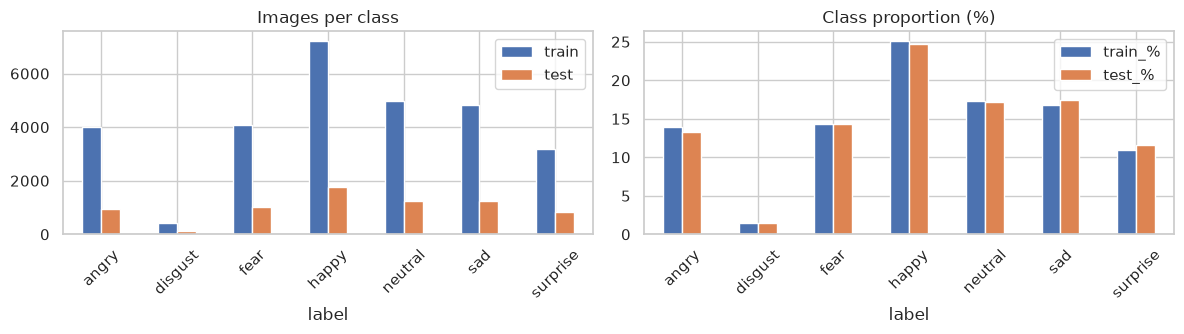

In [0]:
counts = pd.DataFrame(
    {
        "train": df_tr["label"].value_counts(),
        "test": df_te["label"].value_counts(),
    }
).loc[CLASSES]
counts["train_%"] = (100 * counts["train"] / counts["train"].sum()).round(1)
counts["test_%"] = (100 * counts["test"] / counts["test"].sum()).round(1)
print(counts)
print(
    f"\nImbalance ratio (max/min) train: {counts['train'].max() / counts['train'].min():.1f}"
)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
counts[["train", "test"]].plot.bar(ax=ax[0], rot=45)
ax[0].set_title("Images per class")
counts[["train_%", "test_%"]].plot.bar(ax=ax[1], rot=45)
ax[1].set_title("Class proportion (%)")
plt.tight_layout()
plt.show()

## 3. Visual inspection

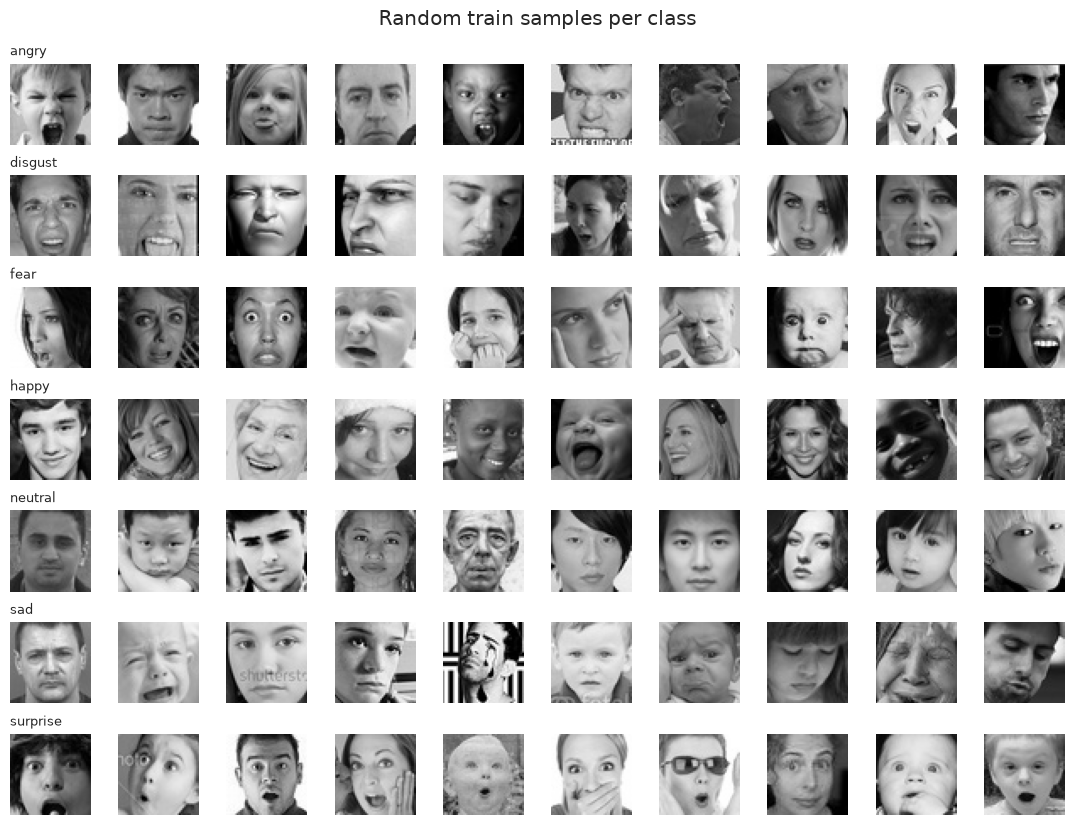

In [0]:
def show_grid(X, y, per_class=10, seed=SEED, title=None):
    r = np.random.default_rng(seed)
    fig, axes = plt.subplots(
        len(CLASSES), per_class, figsize=(per_class * 1.1, len(CLASSES) * 1.2)
    )
    for i, c in enumerate(CLASSES):
        idx = r.choice(np.where(y == i)[0], per_class, replace=False)
        for j, k in enumerate(idx):
            axes[i, j].imshow(X[k], cmap="gray", vmin=0, vmax=255)
            axes[i, j].axis("off")
        axes[i, 0].set_title(c, loc="left", fontsize=9)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


show_grid(X_tr, y_tr, title="Random train samples per class")

## 4. Pixel statistics
Mean / std face per class and brightness / contrast distributions.

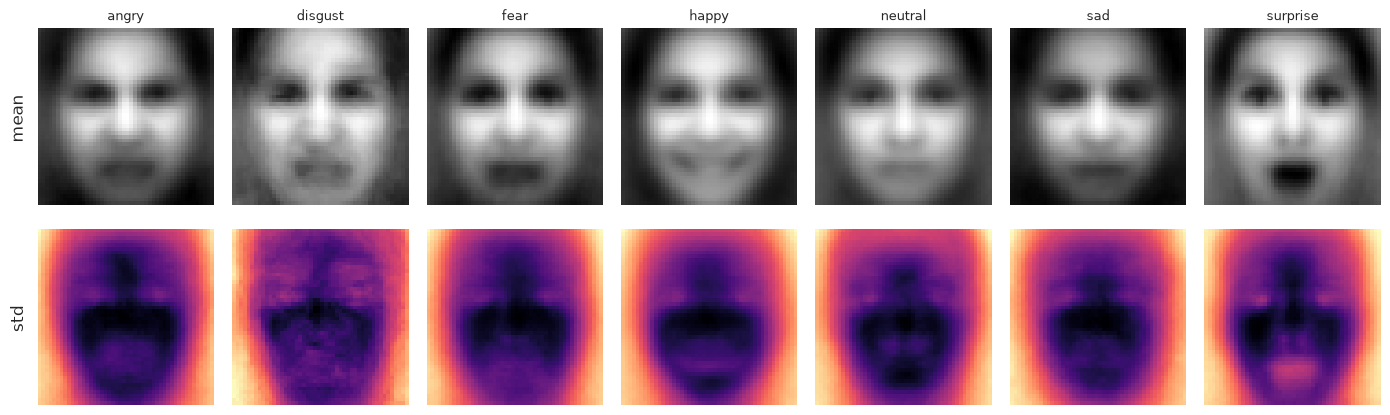

In [0]:
fig, axes = plt.subplots(2, len(CLASSES), figsize=(14, 4.5))
for i, c in enumerate(CLASSES):
    m = X_tr[y_tr == i].astype(np.float32)
    axes[0, i].imshow(m.mean(0), cmap="gray")
    axes[1, i].imshow(m.std(0), cmap="magma")
    axes[0, i].set_title(c, fontsize=9)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].text(-8, 24, "mean", rotation=90, va="center")
axes[1, 0].text(-8, 24, "std", rotation=90, va="center")
plt.tight_layout()
plt.show()

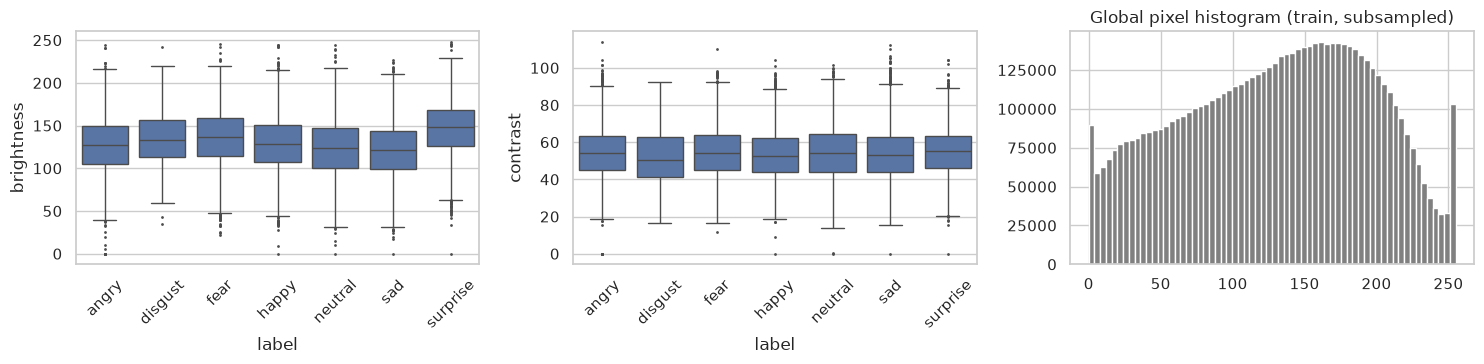

         brightness       contrast      
               mean   std     mean   std
label                                   
angry         126.2  33.2     54.4  13.7
disgust       135.2  33.1     52.2  14.1
fear          135.5  32.4     54.7  13.6
happy         129.4  32.0     53.1  12.9
neutral       123.9  33.2     54.3  14.7
sad           121.3  33.5     53.8  14.1
surprise      146.3  31.7     55.2  12.9


In [0]:
df_tr["brightness"] = X_tr.reshape(len(X_tr), -1).mean(1)
df_tr["contrast"] = X_tr.reshape(len(X_tr), -1).std(1)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.boxplot(data=df_tr, x="label", y="brightness", order=CLASSES, ax=ax[0], fliersize=1)
sns.boxplot(data=df_tr, x="label", y="contrast", order=CLASSES, ax=ax[1], fliersize=1)
ax[2].hist(X_tr[::10].ravel(), bins=64, color="gray")
ax[2].set_title("Global pixel histogram (train, subsampled)")
for a in ax[:2]:
    a.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
print(
    df_tr.groupby("label")[["brightness", "contrast"]]
    .agg(["mean", "std"])
    .round(1)
    .loc[CLASSES]
)

## 5. Data quality and label noise
Exact duplicates (also with *different* labels), train/test leakage and
degenerate (almost flat) images.

In [0]:
def md5(a):
    return hashlib.md5(a.tobytes()).hexdigest()


df_tr["hash"] = [md5(a) for a in X_tr]
df_te["hash"] = [md5(a) for a in X_te]

dup_tr = df_tr[df_tr.duplicated("hash", keep=False)]
conflict = dup_tr.groupby("hash")["label"].nunique()
conflict = conflict[conflict > 1]
leak = set(df_tr["hash"]) & set(df_te["hash"])

print(
    f"Train images that have an exact duplicate in train: {len(dup_tr)} "
    f"({100 * len(dup_tr) / len(df_tr):.2f}%)"
)
print(f"Duplicate groups with CONFLICTING labels: {len(conflict)}")
print(f"Distinct images shared between train and test: {len(leak)}")

flat = df_tr["contrast"] < 10
print(
    f"Almost flat images (std < 10): {flat.sum()} -> {df_tr[flat]['label'].value_counts().to_dict()}"
)

Train images that have an exact duplicate in train: 2271 (7.91%)
Duplicate groups with CONFLICTING labels: 39
Distinct images shared between train and test: 531
Almost flat images (std < 10): 13 -> {'angry': 7, 'happy': 2, 'neutral': 2, 'sad': 1, 'surprise': 1}


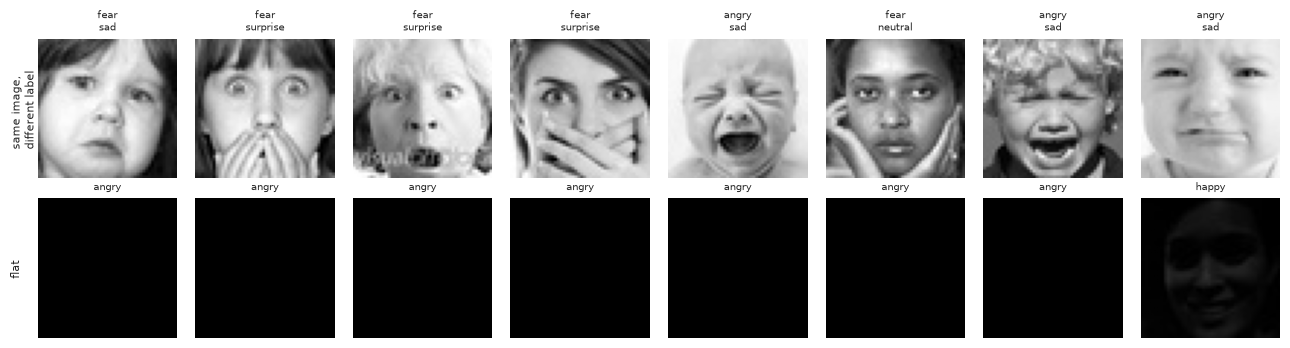

In [0]:
# Examples: conflicting duplicates (same pixels, different label) and flat images
groups = list(conflict.index[:8])
fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for j, h in enumerate(groups):
    sub = df_tr[df_tr["hash"] == h]
    axes[0, j].imshow(X_tr[sub.index[0]], cmap="gray")
    axes[0, j].set_title("\n".join(sorted(sub["label"].unique())), fontsize=7)
for j, k in enumerate(df_tr[flat].index[:8]):
    axes[1, j].imshow(X_tr[k], cmap="gray", vmin=0, vmax=255)
    axes[1, j].set_title(df_tr.loc[k, "label"], fontsize=7)
for a in axes.ravel():
    a.axis("off")
axes[0, 0].text(
    -10, 24, "same image,\ndifferent label", rotation=90, va="center", fontsize=8
)
axes[1, 0].text(-10, 24, "flat", rotation=90, va="center", fontsize=8)
plt.tight_layout()
plt.show()

## 6. Classical features: HOG and LBP
- **HOG**: 9 orientations, 8×8 px cells, 2×2 blocks → 900 dims.
- **LBP**: uniform (P=8, R=1), histogram per cell of a 6×6 grid → 360 dims.

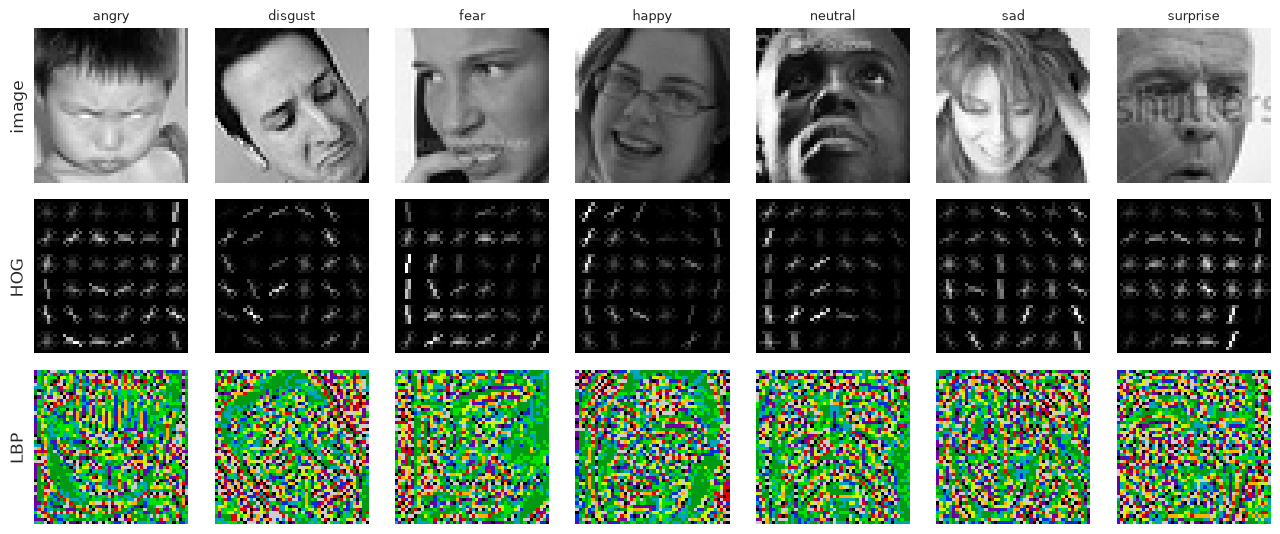

In [0]:
def hog_feat(img):
    return hog(
        img,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
    )


def lbp_feat(img, P=8, R=1, grid=6):
    lbp = local_binary_pattern(img, P, R, method="uniform")
    s = img.shape[0] // grid
    h = [
        np.histogram(
            lbp[i * s : (i + 1) * s, j * s : (j + 1) * s],
            bins=P + 2,
            range=(0, P + 2),
            density=True,
        )[0]
        for i in range(grid)
        for j in range(grid)
    ]
    return np.concatenate(h)


# one example per class
fig, axes = plt.subplots(3, len(CLASSES), figsize=(13, 5.5))
for i, c in enumerate(CLASSES):
    img = X_tr[np.where(y_tr == i)[0][0]]
    _, hog_img = hog(
        img,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        visualize=True,
    )
    axes[0, i].imshow(img, cmap="gray")
    axes[1, i].imshow(hog_img, cmap="gray")
    axes[2, i].imshow(local_binary_pattern(img, 8, 1, "uniform"), cmap="nipy_spectral")
    axes[0, i].set_title(c, fontsize=9)
for a in axes.ravel():
    a.axis("off")
for r, t in enumerate(["image", "HOG", "LBP"]):
    axes[r, 0].text(-8, 24, t, rotation=90, va="center")
plt.tight_layout()
plt.show()

In [0]:
def extract(X, fn):
    return np.array(Parallel(n_jobs=-1, batch_size=256)(delayed(fn)(a) for a in X))


F = {}
for name, fn in [("HOG", hog_feat), ("LBP", lbp_feat)]:
    F[name] = (extract(X_tr, fn), extract(X_te, fn))
F["HOG+LBP"] = tuple(np.hstack([F["HOG"][k], F["LBP"][k]]) for k in range(2))
print({k: v[0].shape[1] for k, v in F.items()})

{'HOG': 900, 'LBP': 360, 'HOG+LBP': 1260}


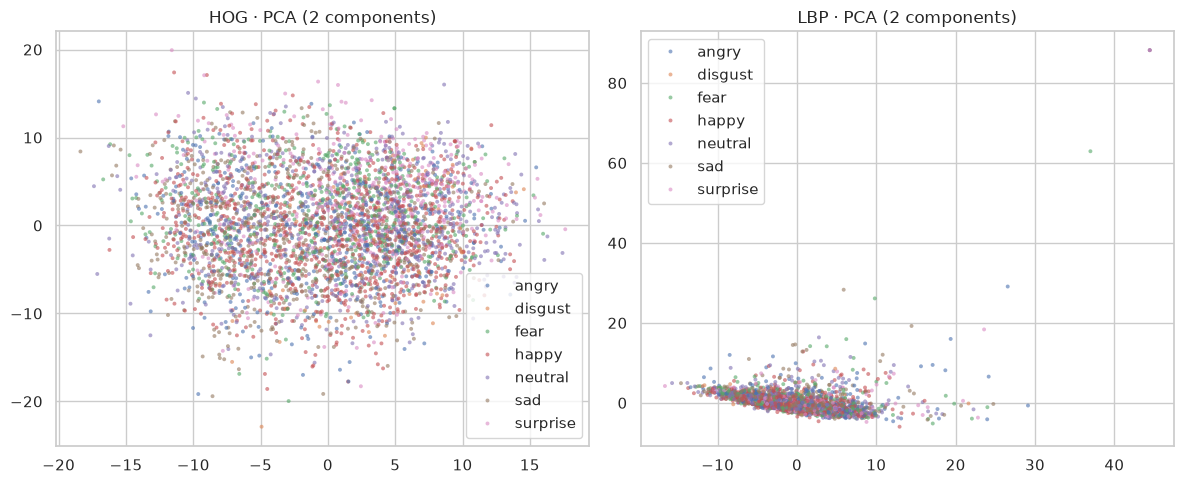

In [0]:
# PCA projection of the features: are classes separable at all?
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sub = rng.choice(len(X_tr), 4000, replace=False)
for ax, name in zip(axes, ["HOG", "LBP"]):
    Z = PCA(2, random_state=SEED).fit_transform(
        StandardScaler().fit_transform(F[name][0][sub])
    )
    sns.scatterplot(
        x=Z[:, 0],
        y=Z[:, 1],
        hue=np.array(CLASSES)[y_tr[sub]],
        hue_order=CLASSES,
        s=8,
        alpha=0.6,
        linewidth=0,
        ax=ax,
    )
    ax.set_title(f"{name} · PCA (2 components)")
plt.tight_layout()
plt.show()

## 7. SVM baseline and confusion matrix
RBF-SVM on a stratified train subsample (speed), evaluated on the whole official test set.

In [0]:
N_SVM = 10000
idx_svm, _ = train_test_split(
    np.arange(len(y_tr)), train_size=N_SVM, stratify=y_tr, random_state=SEED
)

models, preds, scores = {}, {}, {}
for name, (Ftr, Fte) in F.items():
    clf = make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=10,
            gamma="scale",
            class_weight="balanced",
            decision_function_shape="ovr",
        ),
    )
    clf.fit(Ftr[idx_svm], y_tr[idx_svm])
    models[name] = clf
    preds[name] = clf.predict(Fte)
    scores[name] = clf.decision_function(Fte)
    print(
        f"{name:8s} acc={accuracy_score(y_te, preds[name]):.3f}  "
        f"macro-F1={classification_report(y_te, preds[name], output_dict=True)['macro avg']['f1-score']:.3f}  "
        f"kappa={cohen_kappa_score(y_te, preds[name]):.3f}"
    )

HOG      acc=0.504  macro-F1=0.477  kappa=0.396
LBP      acc=0.382  macro-F1=0.348  kappa=0.243
HOG+LBP  acc=0.508  macro-F1=0.480  kappa=0.401


Best features: HOG+LBP
              precision    recall  f1-score   support

       angry      0.386     0.372     0.379       958
     disgust      0.914     0.288     0.438       111
        fear      0.360     0.301     0.328      1024
       happy      0.646     0.760     0.698      1774
     neutral      0.486     0.483     0.485      1233
         sad      0.390     0.417     0.403      1247
    surprise      0.682     0.588     0.632       831

    accuracy                          0.508      7178
   macro avg      0.552     0.459     0.480      7178
weighted avg      0.507     0.508     0.503      7178



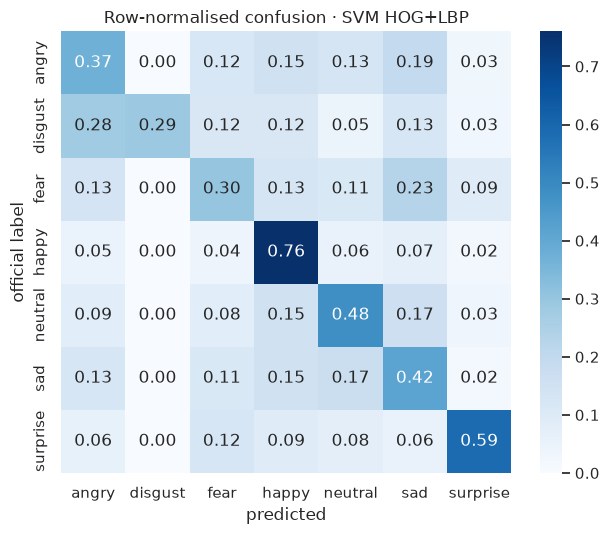

In [0]:
best = max(preds, key=lambda n: accuracy_score(y_te, preds[n]))
print("Best features:", best)
print(classification_report(y_te, preds[best], target_names=CLASSES, digits=3))

cm = confusion_matrix(y_te, preds[best], normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    ax=ax,
)
ax.set(
    xlabel="predicted",
    ylabel="official label",
    title=f"Row-normalised confusion · SVM {best}",
)
plt.tight_layout()
plt.show()

In [0]:
# Most confused pairs (symmetrised off-diagonal mass)
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = pd.Series(
    {
        (CLASSES[i], CLASSES[j]): off[i, j] + off[j, i]
        for i in range(7)
        for j in range(i + 1, 7)
    }
).sort_values(ascending=False)
print(pairs.head(6).round(3))

fear     sad        0.343
neutral  sad        0.340
angry    sad        0.319
         disgust    0.280
         fear       0.253
happy    sad        0.223
dtype: float64


## 8. Label noise: confidently misclassified test faces
Highest-margin SVM errors are candidates for wrong / ambiguous official labels.

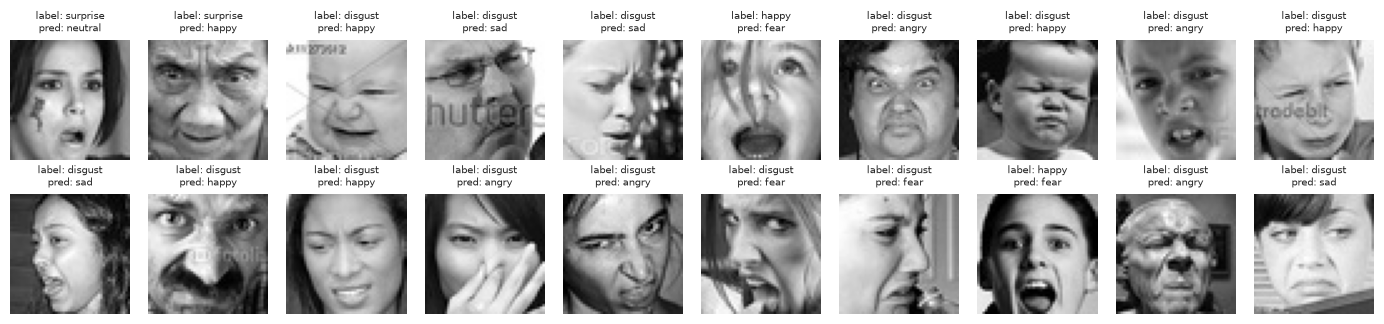

In [0]:
S = scores[best]
pred_best = preds[best]
margin = S[np.arange(len(y_te)), pred_best] - S[np.arange(len(y_te)), y_te]
wrong = np.where(pred_best != y_te)[0]
wrong = wrong[np.argsort(-margin[wrong])]
wrong = wrong[
    ~df_te["hash"].iloc[wrong].duplicated().to_numpy()
]  # drop repeated images
top = wrong[:20]

fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for a, k in zip(axes.ravel(), top):
    a.imshow(X_te[k], cmap="gray")
    a.set_title(f"label: {CLASSES[y_te[k]]}\npred: {CLASSES[pred_best[k]]}", fontsize=7)
    a.axis("off")
plt.tight_layout()
plt.show()

## 9. Human annotation of 60 faces and Cohen's κ
1. Run the next cell once: it saves `annotation_sheet.png` (60 anonymous test faces) and an empty `annotations.csv`.
2. Each annotator fills one `annotator_*` column in `annotations.csv` with one of the 7 labels (without looking at the official ones).
3. Re-run the κ cell below.

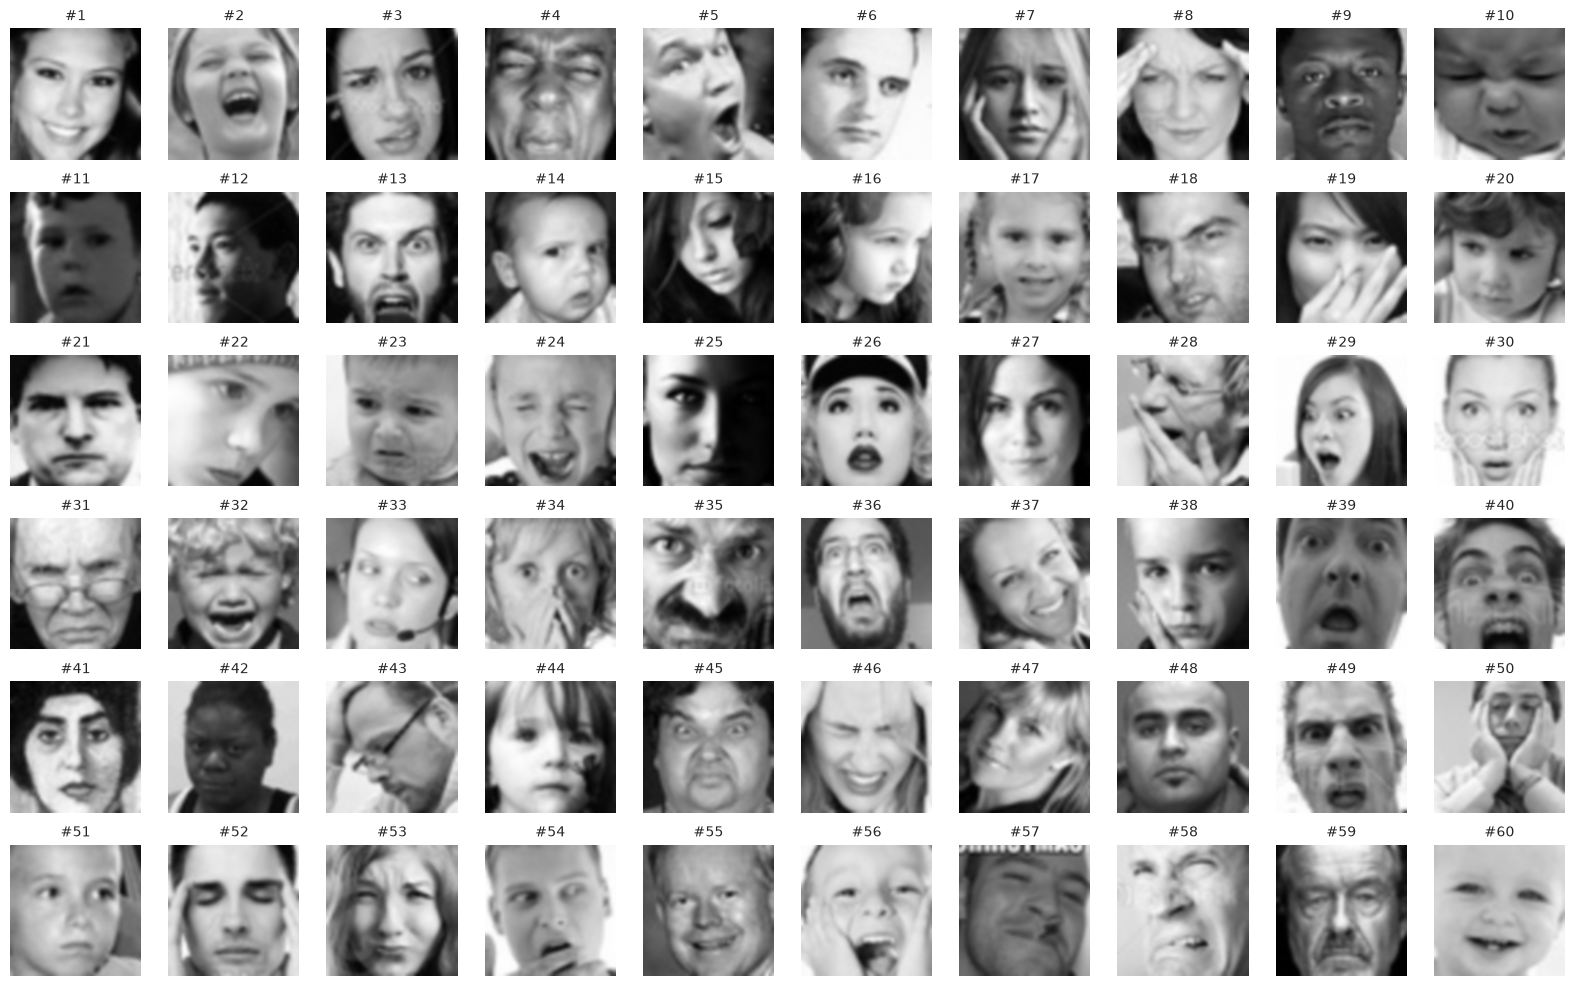

Labels: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [0]:
per_class = [9, 9, 9, 9, 8, 8, 8]
first = ~df_te["hash"].duplicated().to_numpy()  # never show the same image twice
sel = np.concatenate(
    [
        rng.choice(np.where((y_te == i) & first)[0], n, replace=False)
        for i, n in enumerate(per_class)
    ]
)
sel = rng.permutation(sel)
ids = np.arange(1, 61)

official = pd.DataFrame(
    {
        "id": ids,
        "test_index": sel,
        "official": np.array(CLASSES)[y_te[sel]],
        "svm": np.array(CLASSES)[preds[best][sel]],
    }
)
official.to_csv("official_labels.csv", index=False)

if not Path("annotations.csv").exists():
    pd.DataFrame({"id": ids, "annotator_1": "", "annotator_2": ""}).to_csv(
        "annotations.csv", index=False
    )

fig, axes = plt.subplots(6, 10, figsize=(16, 10))
for a, i, k in zip(axes.ravel(), ids, sel):
    a.imshow(X_te[k], cmap="gray", interpolation="bicubic")
    a.set_title(f"#{i}", fontsize=10)
    a.axis("off")
plt.tight_layout()
plt.savefig("annotation_sheet.png", dpi=110)
plt.show()
print("Labels:", CLASSES)